# 05 - Model Exploration 

**Goal:** Explore five models spanning linear, tree-based, and neural network 
approaches. Compare the best configuration per model, then shortlist candidates for deeper 
tuning in the next stage.

**Key design decisions:**
- Each model tuned over a small, systematic grid — not hand-picked values
- Best configuration selected by validation AUC
- `class_weight='balanced'` (or `scale_pos_weight`) and `random_state=42` throughout

---
## 1. Setup

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import os

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.neural_network import MLPClassifier

from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix, roc_curve,
    log_loss
)

# Project utilities
import sys
sys.path.insert(0, "../src")
from utils import (
    save_fig, set_plot_style,
    SEED, FIG_DIR, DATA_DIR,
    OVERALL_RATING_COL, SUB_RATING_COLS, ALL_RATING_COLS 
)

# Apply consistent styling
set_plot_style()
np.random.seed(SEED)

# Display options
pd.set_option('display.max_columns', 30)

print('Setup complete.')

Setup complete.


---
## 5.2 Data Loading & Feature Assembly

Load structured features (CSVs) and topic probability features (.npy) from
notebook 04. Combine into a single feature matrix per split.

In [3]:
# Load data
df_train = pd.read_csv(os.path.join(DATA_DIR, 'train.csv'))
df_val   = pd.read_csv(os.path.join(DATA_DIR, 'val.csv'))

topic_train = np.load(os.path.join(DATA_DIR, 'train_topic_features.npy'))
topic_val   = np.load(os.path.join(DATA_DIR, 'val_topic_features.npy'))

print(f'Train:  {df_train.shape}  Topics: {topic_train.shape}')
print(f'Val:    {df_val.shape}  Topics: {topic_val.shape}')

Train:  (440112, 27)  Topics: (440112, 117)
Val:    (94310, 27)  Topics: (94310, 117)


In [4]:
# --- 3. Feature Assembly ---

# Target
y_train = df_train['recommend_binary'].values
y_val   = df_val['recommend_binary'].values

# Structured features
DROP_COLS = ['pros', 'cons', 'recommend_binary']
struct_train = df_train.drop(columns=DROP_COLS)
struct_val   = df_val.drop(columns=DROP_COLS)

# Feature names
structured_feature_names = list(struct_train.columns)
topic_feature_names = np.load(os.path.join(DATA_DIR, 'topic_feature_names.npy'), allow_pickle=True).tolist()
all_feature_names = structured_feature_names + topic_feature_names

# Concatenate structured + topic
X_train = np.concatenate([struct_train.values, topic_train], axis=1)
X_val   = np.concatenate([struct_val.values, topic_val], axis=1)

# Verify
print(f'Structured: {len(structured_feature_names)} | Topics: {len(topic_feature_names)} | Total: {len(all_feature_names)}')
print(f'X_train: {X_train.shape}  y_train: {y_train.shape}  (pos rate: {y_train.mean():.3f})')
print(f'X_val:   {X_val.shape}  y_val:   {y_val.shape}  (pos rate: {y_val.mean():.3f})')
print(f'NaN check — train: {np.isnan(X_train).sum()}, val: {np.isnan(X_val).sum()}')

Structured: 24 | Topics: 117 | Total: 141
X_train: (440112, 141)  y_train: (440112,)  (pos rate: 0.604)
X_val:   (94310, 141)  y_val:   (94310,)  (pos rate: 0.604)
NaN check — train: 0, val: 0


---
## 5.2 Preprocessing

Scale continuous features (sub-ratings, firm encoding, topic probabilities) to zero
mean and unit variance. Binary/dummy features pass through unchanged.

Scaler fit on training data only to prevent data leakage.

In [9]:
# Preprocessing

CONTINUOUS_COLS = ALL_RATING_COLS + ['firm_encoded'] + topic_feature_names
BINARY_COLS = [
    'is_current',
    'ceo_approv_Disapprove', 'ceo_approv_Mild', 'ceo_approv_No Opinion',
    'seniority_level_Management', 'seniority_level_Other',
    'seniority_level_Senior', 'seniority_level_Unknown',
    'review_year_2013', 'review_year_2014', 'review_year_2015',
    'review_year_2016', 'review_year_2017', 'review_year_2018', 
    'review_year_2019', 'review_year_2020', 'review_year_2021',
]

# Verify all structured features accounted for
assert set(ALL_RATING_COLS + ['firm_encoded'] + BINARY_COLS) == set(structured_feature_names), \
    f"Missing: {set(structured_feature_names) - set(ALL_RATING_COLS + ['firm_encoded'] + BINARY_COLS)}"

# Convert arrays to DataFrames
X_train_df = pd.DataFrame(X_train, columns=all_feature_names)
X_val_df   = pd.DataFrame(X_val, columns=all_feature_names)

# Build the preprocessor
preprocessor = ColumnTransformer([
    ('scale', StandardScaler(), CONTINUOUS_COLS),
    ('pass',  'passthrough',    BINARY_COLS)
])

# Fit on train, transform both
X_train_scaled = preprocessor.fit_transform(X_train_df)
X_val_scaled   = preprocessor.transform(X_val_df)

print(f'Scaled — Train: {X_train_scaled.shape}, Val: {X_val_scaled.shape}')
print(f'Continuous mean (first 3): {X_train_scaled[:, :3].mean(axis=0).round(6)}')
print(f'Continuous std  (first 3): {X_train_scaled[:, :3].std(axis=0).round(6)}')

Scaled — Train: (440112, 141), Val: (94310, 141)
Continuous mean (first 3): [ 0. -0. -0.]
Continuous std  (first 3): [1. 1. 1.]


---
## 5.3 Metric Hierarchy & Selection Criteria

### Metric Choices

| Priority | Metric | Justification |
|----------|--------|---------------|
| **Primary** | ROC-AUC | Threshold-independent measure of discrimination. Evaluates full ranking quality rather than a single operating point. Appropriate for the moderate 60/40 class split. |
| **Secondary** | F1 Score | Balances precision and recall at the default 0.5 decision threshold. Provides a concrete performance measure for practical comparison. |
| **Diagnostic** | Precision, Recall, Confusion Matrix | Reveal *how* models differ — e.g., whether errors lean toward false positives or false negatives. Not used for ranking. |

### Class Weights

Class weights (`class_weight='balanced'` or `scale_pos_weight`) address the 60/40 
class imbalance, ensuring models do not simply favour the majority class.

### Shortlisting Approach

Shortlist based on AUC ranking, with consideration of F1, overfitting gap 
(train − validation accuracy), training time, and interpretability. Given the 
research question focuses on understanding what drives recommendations, 
interpretable models are prioritised alongside one complex model for comparison.

---
## 5.4 Evaluation Harness

Two evaluation functions are used. `quick_eval()` is lightweight, returning only 
AUC, F1, and accuracy for grid search iterations. `evaluate_model()` provides full 
evaluation with all metrics, classification report, and storage in `results_log`, 
used for the best configuration per family.

In [22]:
# --- 4. Evaluation Harness ---
results_log = []
model_predictions = {}


def quick_eval(model, X_tr, y_tr, X_v, y_v):
    """
    Lightweight evaluation for grid search iterations.
    
    Fits model, computes core metrics on train and validation sets.
    Returns dict with AUC, F1, accuracy, log loss, and training time.
    Does not store results or print output.
    """
    t0 = time.time()
    model.fit(X_tr, y_tr)
    train_time = time.time() - t0

    # Predictions on both sets
    y_tr_pred = model.predict(X_tr)
    y_tr_proba = model.predict_proba(X_tr)[:, 1]
    y_v_pred = model.predict(X_v)
    y_v_proba = model.predict_proba(X_v)[:, 1]

    return {
        'AUC': roc_auc_score(y_v, y_v_proba),
        'Train AUC': roc_auc_score(y_tr, y_tr_proba),
        'F1': f1_score(y_v, y_v_pred),
        'Acc': accuracy_score(y_v, y_v_pred),
        'Train Acc': accuracy_score(y_tr, y_tr_pred),
        'Train LL': log_loss(y_tr, y_tr_proba),
        'Val LL': log_loss(y_v, y_v_proba),
        'Time': round(train_time, 1),
    }


def evaluate_model(model, X_tr, y_tr, X_v, y_v, model_name, config_str=''):
    """
    Full evaluation for best configuration per model family.
    
    Fits model, computes all metrics, prints classification report,
    and stores results in results_log and model_predictions for
    later comparison and visualisation.
    """
    # Train and time
    t0 = time.time()
    model.fit(X_tr, y_tr)
    train_time = time.time() - t0

    # Predictions
    y_tr_pred = model.predict(X_tr)
    y_tr_proba = model.predict_proba(X_tr)[:, 1] if hasattr(model, 'predict_proba') else None
    y_v_pred = model.predict(X_v)
    y_v_proba = model.predict_proba(X_v)[:, 1] if hasattr(model, 'predict_proba') else None

    # Compute metrics
    train_acc = accuracy_score(y_tr, y_tr_pred)
    train_auc = roc_auc_score(y_tr, y_tr_proba) if y_tr_proba is not None else None
    val_acc = accuracy_score(y_v, y_v_pred)
    val_prec = precision_score(y_v, y_v_pred)
    val_rec = recall_score(y_v, y_v_pred)
    val_f1 = f1_score(y_v, y_v_pred)
    val_auc = roc_auc_score(y_v, y_v_proba) if y_v_proba is not None else None
    overfit_gap = train_auc - val_auc if (train_auc and val_auc) else None

    # Store in results log
    metrics = {
        'Model': model_name,
        'Best Config': config_str,
        'Train AUC': train_auc,
        'Val AUC': val_auc,
        'Overfit Gap': overfit_gap,
        'Precision': val_prec,
        'Recall': val_rec,
        'F1': val_f1,
        'Train Time (s)': round(train_time, 1),
    }
    results_log.append(metrics)

    # Store predictions for comparison plots
    model_predictions[model_name] = {
        'y_pred': y_v_pred,
        'y_proba': y_v_proba,
    }

    # Print summary
    print(f'{model_name}  [{config_str}]')
    print('=' * 55)
    print(f'  ROC-AUC:    {val_auc:.4f}  (train: {train_auc:.4f}, gap: {overfit_gap:+.4f})')
    print(f'  Accuracy:   {val_acc:.4f}')
    print(f'  Precision:  {val_prec:.4f}')
    print(f'  Recall:     {val_rec:.4f}')
    print(f'  F1 Score:   {val_f1:.4f}')
    print(f'  Train time: {train_time:.1f}s')
    print()
    print(classification_report(y_v, y_v_pred, target_names=['Not Recommend', 'Recommend']))

    return {
        'y_pred': y_v_pred,
        'y_proba': y_v_proba,
        'metrics': metrics,
        'model': model,
    }


print('Evaluation harness ready.')

Evaluation harness ready.


---
## 5.5 Baseline

A majority class classifier always predicts the most frequent label (Recommend, 60% of cases). 
This sets the performance floor with AUC = 0.5, representing no discriminative ability. 
Any useful model must clearly beat this baseline.

In [23]:
# Majority-class baseline
dummy = DummyClassifier(strategy='most_frequent')
res_majority = evaluate_model(dummy, X_train_scaled, y_train,
                              X_val_scaled, y_val, 'Majority Class',
                              config_str='strategy=most_frequent')

Majority Class  [strategy=most_frequent]
  ROC-AUC:    0.5000  (train: 0.5000, gap: +0.0000)
  Accuracy:   0.6041
  Precision:  0.6041
  Recall:     1.0000
  F1 Score:   0.7532
  Train time: 0.0s

               precision    recall  f1-score   support

Not Recommend       0.00      0.00      0.00     37342
    Recommend       0.60      1.00      0.75     56968

     accuracy                           0.60     94310
    macro avg       0.30      0.50      0.38     94310
 weighted avg       0.36      0.60      0.45     94310



c:\Users\anama\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\anama\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\anama\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


---
## 5.6 Models with Light Tuning

Each model is tuned over its primary complexity parameter, with XGBoost searched across a depth × learning rate grid. 
The best configuration per model is selected by validation AUC.

| Section | Model | Parameter(s) | Grid | Justification |
|---------|-------|--------------|------|---------------|
| 6.1 | Logistic Regression | C (L2 strength) | 0.01, 0.1, 1, 10, 100 | Primary regularisation knob |
| 6.2 | Decision Tree | max_depth | 3, 5, 7, 10, None | Controls tree complexity |
| 6.3 | Random Forest | max_depth | 5, 10, 20, None | Depth matters in ensembles |
| 6.4 | XGBoost | max_depth × learning_rate | [3, 6, 10] × [0.01, 0.1, 0.3] | Depth + boosting step size |
| 6.5 | MLP | hidden_layer_sizes | (50,), (100,), (100, 50) | Architecture controls capacity |


### 5.6.1 Logistic Regression

In [ ]:
# Logistic Regression
C_values = [0.01, 0.1, 1, 10, 100]
lr_results = []

print('Logistic Regression — L2 Regularisation Grid')
print('=' * 55)

# Search over regularisation strength
for c in C_values:
    model = LogisticRegression(C=c, class_weight='balanced',
                               random_state=SEED, max_iter=1000)
    r = quick_eval(model, X_train_scaled, y_train, X_val_scaled, y_val)
    r['C'] = c
    lr_results.append(r)
    print(f'  C={c:<6}  AUC={r["AUC"]:.4f}  TrainAUC={r["Train AUC"]:.4f}  '
      f'Acc={r["Acc"]:.4f}  TrainAcc={r["Train Acc"]:.4f}')

# Select best config by validation AUC
lr_df = pd.DataFrame(lr_results)
best_c = lr_df.loc[lr_df['AUC'].idxmax(), 'C']
print(f'\nBest C by AUC: {best_c}')

# Full evaluation on best config
lr_best = LogisticRegression(C=best_c, class_weight='balanced',
                             random_state=SEED, max_iter=1000)
res_lr = evaluate_model(lr_best, X_train_scaled, y_train,
                        X_val_scaled, y_val, 'Logistic Regression',
                        config_str=f'C={best_c}')

Logistic Regression — L2 Regularisation Grid
  C=0.01    AUC=0.9079  TrainAUC=0.9082  Acc=0.8207  TrainAcc=0.8205
  C=0.1     AUC=0.9078  TrainAUC=0.9082  Acc=0.8207  TrainAcc=0.8205
  C=1       AUC=0.9078  TrainAUC=0.9082  Acc=0.8207  TrainAcc=0.8204
  C=10      AUC=0.9078  TrainAUC=0.9082  Acc=0.8207  TrainAcc=0.8204
  C=100     AUC=0.9078  TrainAUC=0.9082  Acc=0.8207  TrainAcc=0.8204

Best C by AUC: 0.01
Logistic Regression  [C=0.01]
  ROC-AUC:    0.9079  (train: 0.9082, gap: +0.0003)
  Accuracy:   0.8207
  Precision:  0.8748
  Recall:     0.8206
  F1 Score:   0.8468
  Train time: 2.5s

               precision    recall  f1-score   support

Not Recommend       0.75      0.82      0.78     37342
    Recommend       0.87      0.82      0.85     56968

     accuracy                           0.82     94310
    macro avg       0.81      0.82      0.82     94310
 weighted avg       0.83      0.82      0.82     94310



In [27]:
# Sanity check, 0.91 AUC with no signs of overfitting warrants verification
# If any single feature predicts too well, it may indicate leakage.

check_features = (
    ALL_RATING_COLS + 
    ['firm_encoded', 'is_current'] +
    [c for c in structured_feature_names if c.startswith('ceo_approv')]
)

for col in check_features:
    idx = all_feature_names.index(col)
    X_single = X_train_scaled[:, idx].reshape(-1, 1)
    X_single_val = X_val_scaled[:, idx].reshape(-1, 1)
    
    lr = LogisticRegression(random_state=SEED)
    lr.fit(X_single, y_train)
    auc = roc_auc_score(y_val, lr.predict_proba(X_single_val)[:, 1])
    print(f'{col}: AUC = {auc:.4f}')

overall_rating: AUC = 0.8271
work_life_balance: AUC = 0.7143
culture_values: AUC = 0.7963
career_opp: AUC = 0.7673
comp_benefits: AUC = 0.7251
senior_mgmt: AUC = 0.7960
firm_encoded: AUC = 0.6193
is_current: AUC = 0.5085
ceo_approv_Disapprove: AUC = 0.5070
ceo_approv_Mild: AUC = 0.5036
ceo_approv_No Opinion: AUC = 0.5119


**Result:** No leakage detected. Sub-ratings (AUC 0.71–0.83) provide the main signal. 
Firm encoding (0.62), CEO approval, and metadata features (0.50–0.51) add minimal 
independent signal.

### 5.6.2 Decision Tree

The grid includes `max_depth=None` (library default) to demonstrate overfitting 
behaviour. This configuration will achieve near-perfect training accuracy but 
poor validation performance, motivating the need for depth control.

In [ ]:
# Decision Tree 
depths = [3, 5, 7, 10, None]
dt_results = []

print('Decision Tree — max_depth Grid')
print('=' * 55)

# Search over tree depth
for d in depths:
    model = DecisionTreeClassifier(max_depth=d, class_weight='balanced',
                                   random_state=SEED)
    r = quick_eval(model, X_train_scaled, y_train, X_val_scaled, y_val)
    r['max_depth'] = d
    dt_results.append(r)
    print(f'  max_depth={str(d):<5}  AUC={r["AUC"]:.4f}  TrainAUC={r["Train AUC"]:.4f}  '
          f'Acc={r["Acc"]:.4f}  TrainAcc={r["Train Acc"]:.4f}')

# Select best config by validation AUC
dt_df = pd.DataFrame(dt_results)
best_depth = dt_df.loc[dt_df['AUC'].idxmax(), 'max_depth']
best_depth_int = None if pd.isna(best_depth) or best_depth is None else int(best_depth)
print(f'\nBest max_depth by AUC: {best_depth}')

# Full evaluation on best config
dt_best = DecisionTreeClassifier(max_depth=best_depth_int, class_weight='balanced',
                                 random_state=SEED)
res_dt = evaluate_model(dt_best, X_train_scaled, y_train,
                        X_val_scaled, y_val, 'Decision Tree',
                        config_str=f'max_depth={best_depth}')

Decision Tree — max_depth Grid
  max_depth=3      AUC=0.8888  TrainAUC=0.8894  Acc=0.7921  TrainAcc=0.7926
  max_depth=5      AUC=0.9078  TrainAUC=0.9077  Acc=0.8219  TrainAcc=0.8221
  max_depth=7      AUC=0.9130  TrainAUC=0.9140  Acc=0.8159  TrainAcc=0.8171
  max_depth=10     AUC=0.9115  TrainAUC=0.9210  Acc=0.8228  TrainAcc=0.8321
  max_depth=None   AUC=0.7678  TrainAUC=1.0000  Acc=0.7781  TrainAcc=1.0000

Best max_depth by AUC: 7.0
Decision Tree  [max_depth=7.0]
  ROC-AUC:    0.9130  (train: 0.9140, gap: +0.0010)
  Accuracy:   0.8159
  Precision:  0.9166
  Recall:     0.7649
  F1 Score:   0.8339
  Train time: 28.9s

               precision    recall  f1-score   support

Not Recommend       0.71      0.89      0.79     37342
    Recommend       0.92      0.76      0.83     56968

     accuracy                           0.82     94310
    macro avg       0.82      0.83      0.81     94310
 weighted avg       0.84      0.82      0.82     94310



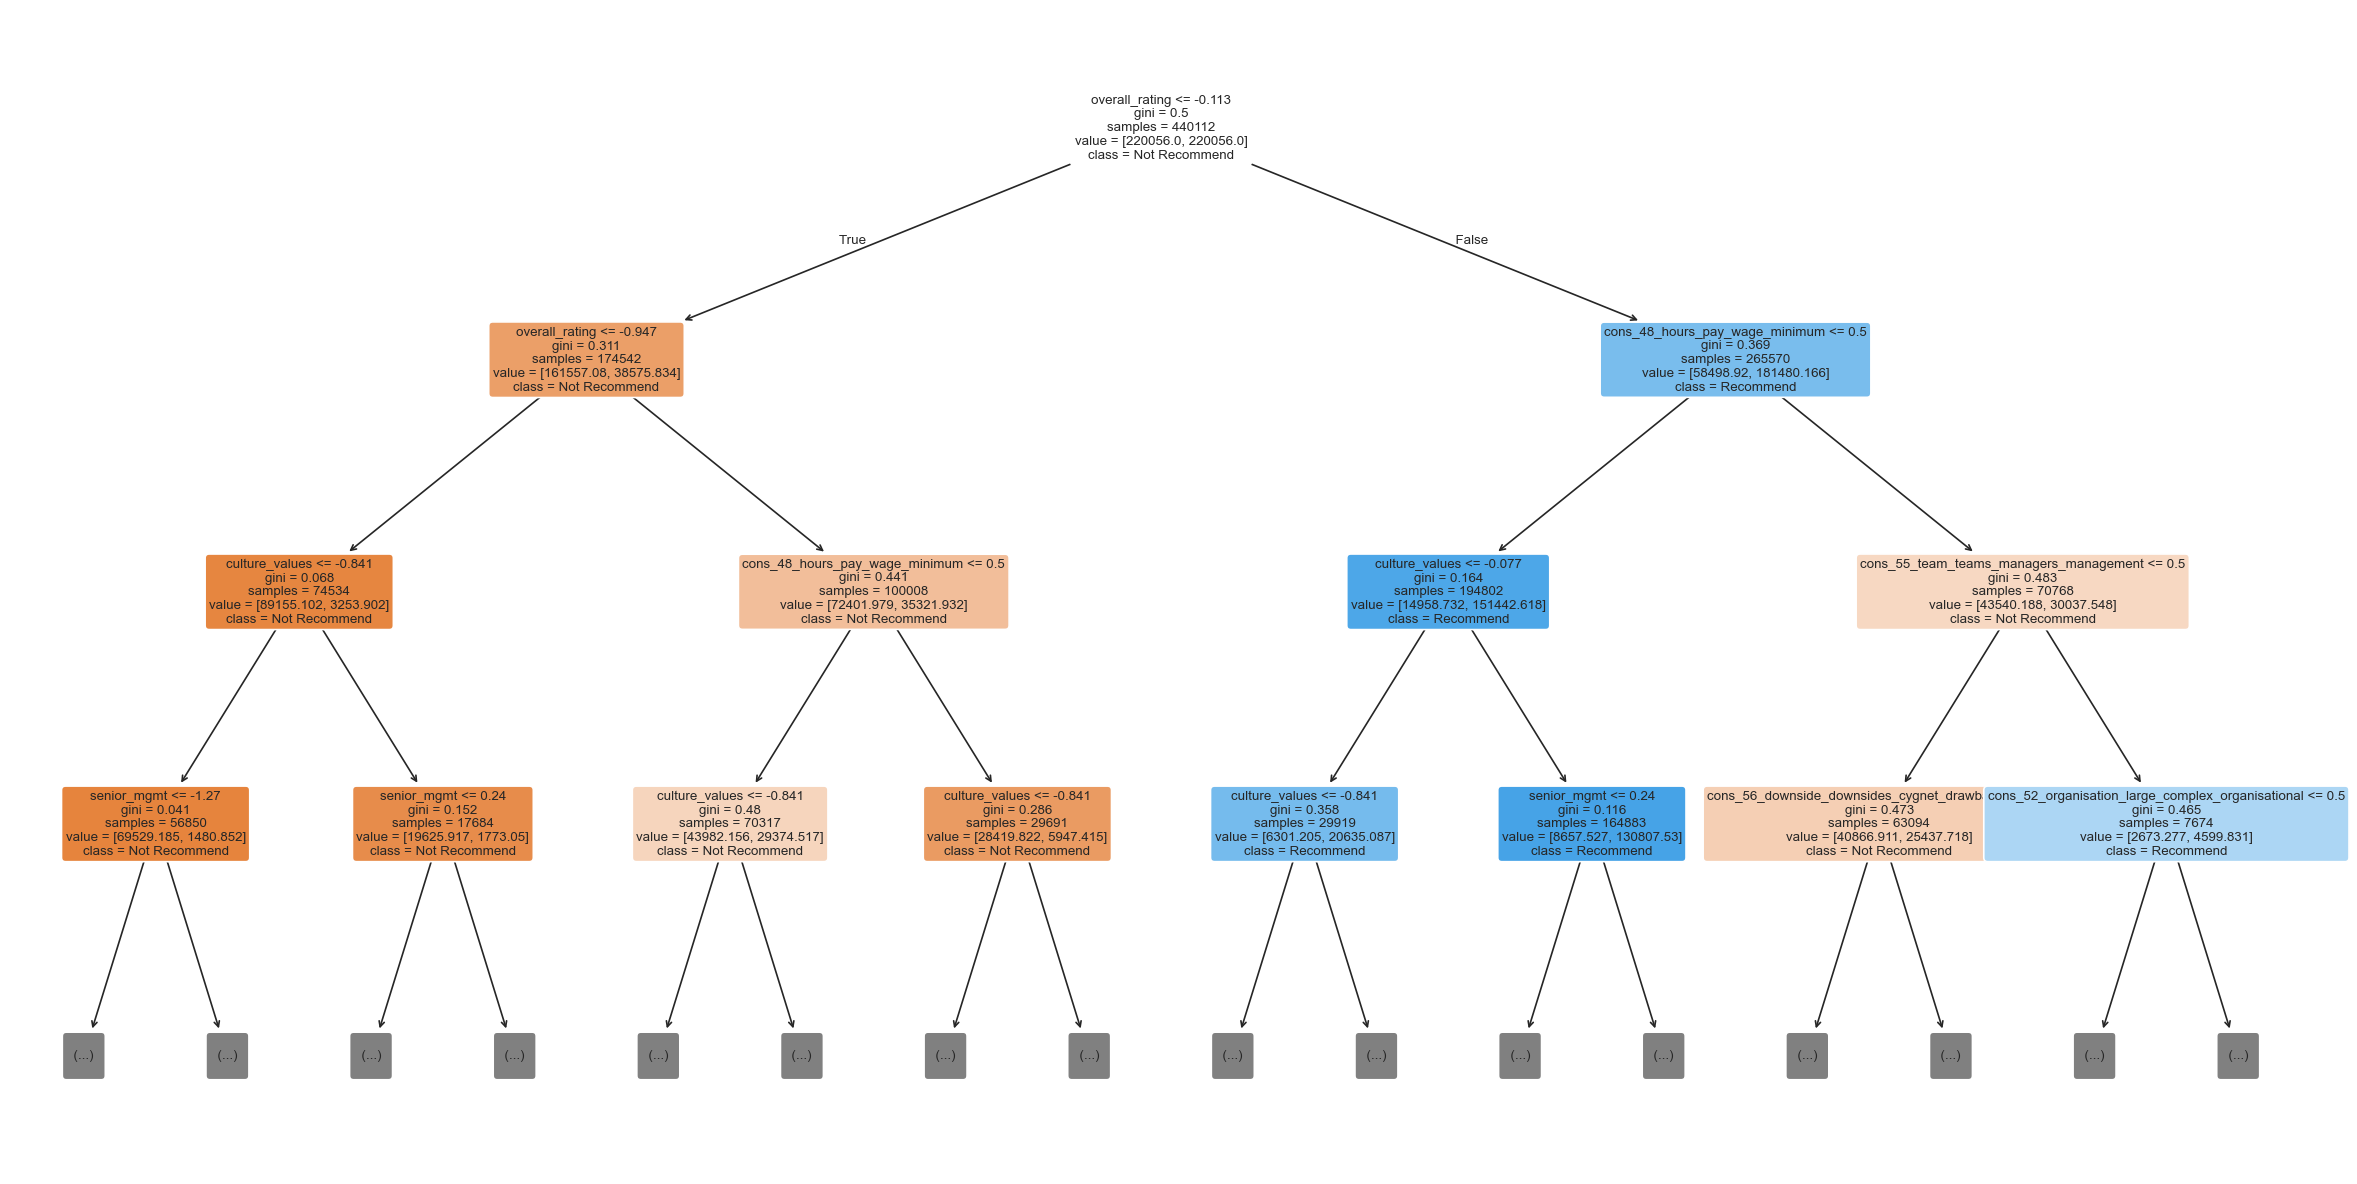

In [ ]:
# Decision tree structure (top 3 levels)
fig, ax = plt.subplots(figsize=(20, 10))
plot_tree(res_dt['model'], max_depth=3, feature_names=all_feature_names,
          class_names=['Not Recommend', 'Recommend'],
          filled=True, rounded=True, ax=ax, fontsize=8)
plt.tight_layout()
save_fig('explore_dt_structure')
plt.show()

### 5.6.3 Random Forest

In [ ]:
# Random Forest
rf_depths = [5, 10, 20, None]
rf_results = []

print('Random Forest — max_depth Grid')
print('=' * 55)

# Search over tree depth
for d in rf_depths:
    model = RandomForestClassifier(max_depth=d, class_weight='balanced',
                                   random_state=SEED, n_jobs=-1)
    r = quick_eval(model, X_train_scaled, y_train, X_val_scaled, y_val)
    r['max_depth'] = d
    rf_results.append(r)
    print(f'  max_depth={str(d):<5}  AUC={r["AUC"]:.4f}  TrainAUC={r["Train AUC"]:.4f}  '
          f'Acc={r["Acc"]:.4f}  TrainAcc={r["Train Acc"]:.4f}')

# Select best config by validation AUC
rf_df = pd.DataFrame(rf_results)
best_rf_depth = rf_df.loc[rf_df['AUC'].idxmax(), 'max_depth']
best_rf_depth_int = None if pd.isna(best_rf_depth) or best_rf_depth is None else int(best_rf_depth)
print(f'\nBest max_depth by AUC: {best_rf_depth}')

# Full evaluation on best config
rf_best = RandomForestClassifier(max_depth=best_rf_depth_int, class_weight='balanced',
                                 random_state=SEED, n_jobs=-1)
res_rf = evaluate_model(rf_best, X_train_scaled, y_train,
                        X_val_scaled, y_val, 'Random Forest',
                        config_str=f'max_depth={best_rf_depth}')

Random Forest — max_depth Grid
  max_depth=5      AUC=0.8980  TrainAUC=0.8975  Acc=0.8082  TrainAcc=0.8061
  max_depth=10     AUC=0.9085  TrainAUC=0.9133  Acc=0.8172  TrainAcc=0.8221
  max_depth=20     AUC=0.9150  TrainAUC=0.9782  Acc=0.8308  TrainAcc=0.9228
  max_depth=None   AUC=0.9133  TrainAUC=1.0000  Acc=0.8295  TrainAcc=1.0000

Best max_depth by AUC: 20.0
Random Forest  [max_depth=20.0]
  ROC-AUC:    0.9150  (train: 0.9782, gap: +0.0632)
  Accuracy:   0.8308
  Precision:  0.8791
  Recall:     0.8347
  F1 Score:   0.8563
  Train time: 32.2s

               precision    recall  f1-score   support

Not Recommend       0.77      0.82      0.79     37342
    Recommend       0.88      0.83      0.86     56968

     accuracy                           0.83     94310
    macro avg       0.82      0.83      0.83     94310
 weighted avg       0.83      0.83      0.83     94310



### 5.6.4 XGBoost

`scale_pos_weight` is the XGBoost equivalent of `class_weight='balanced'`.
Grid searches over `max_depth` and `learning_rate` (9 combinations).

In [31]:
# XGBoost
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
spw = neg_count / pos_count
print(f'scale_pos_weight: {spw:.3f}')

xgb_depths = [3, 6, 10]
xgb_lrs = [0.01, 0.1, 0.3]
xgb_results = []

print('\nXGBoost — max_depth x learning_rate Grid')
print('=' * 65)

# Grid search over depth and learning rate
for d in xgb_depths:
    for lr in xgb_lrs:
        model = XGBClassifier(max_depth=d, learning_rate=lr,
                              scale_pos_weight=spw, random_state=SEED,
                              n_jobs=-1, eval_metric='logloss')
        r = quick_eval(model, X_train_scaled, y_train, X_val_scaled, y_val)
        r['max_depth'] = d
        r['learning_rate'] = lr
        xgb_results.append(r)
        print(f'  depth={d}, lr={lr:<4}  AUC={r["AUC"]:.4f}  TrainAUC={r["Train AUC"]:.4f}  '
              f'Acc={r["Acc"]:.4f}  TrainAcc={r["Train Acc"]:.4f}')

# Select best config by validation AUC
xgb_df = pd.DataFrame(xgb_results)
best_idx = xgb_df['AUC'].idxmax()
best_xgb_depth = int(xgb_df.loc[best_idx, 'max_depth'])
best_xgb_lr = xgb_df.loc[best_idx, 'learning_rate']
print(f'\nBest config by AUC: max_depth={best_xgb_depth}, learning_rate={best_xgb_lr}')

# Full evaluation on best config
xgb_best = XGBClassifier(max_depth=best_xgb_depth, learning_rate=best_xgb_lr,
                         scale_pos_weight=spw, random_state=SEED,
                         n_jobs=-1, eval_metric='logloss')
res_xgb = evaluate_model(xgb_best, X_train_scaled, y_train,
                         X_val_scaled, y_val, 'XGBoost',
                         config_str=f'depth={best_xgb_depth}, lr={best_xgb_lr}')

scale_pos_weight: 0.656

XGBoost — max_depth x learning_rate Grid
  depth=3, lr=0.01  AUC=0.9075  TrainAUC=0.9072  Acc=0.7976  TrainAcc=0.7978
  depth=3, lr=0.1   AUC=0.9184  TrainAUC=0.9189  Acc=0.8258  TrainAcc=0.8266
  depth=3, lr=0.3   AUC=0.9193  TrainAUC=0.9207  Acc=0.8288  TrainAcc=0.8315
  depth=6, lr=0.01  AUC=0.9153  TrainAUC=0.9160  Acc=0.8223  TrainAcc=0.8230
  depth=6, lr=0.1   AUC=0.9204  TrainAUC=0.9237  Acc=0.8306  TrainAcc=0.8348
  depth=6, lr=0.3   AUC=0.9199  TrainAUC=0.9304  Acc=0.8311  TrainAcc=0.8441
  depth=10, lr=0.01  AUC=0.9178  TrainAUC=0.9255  Acc=0.8278  TrainAcc=0.8362
  depth=10, lr=0.1   AUC=0.9204  TrainAUC=0.9435  Acc=0.8329  TrainAcc=0.8595
  depth=10, lr=0.3   AUC=0.9163  TrainAUC=0.9622  Acc=0.8298  TrainAcc=0.8910

Best config by AUC: max_depth=10, learning_rate=0.1
XGBoost  [depth=10, lr=0.1]
  ROC-AUC:    0.9204  (train: 0.9435, gap: +0.0232)
  Accuracy:   0.8329
  Precision:  0.8979
  Recall:     0.8161
  F1 Score:   0.8551
  Train time: 17.8s



### 5.6.5 MLP Neural Network

Grid over `hidden_layer_sizes`, the primary capacity control for MLPs. 
Note that MLPClassifier does not support class weighting.

In [32]:
# MLP
architectures = [(50,), (100,), (100, 50)]
mlp_results = []

print('MLP — Architecture Grid')
print('=' * 55)

# Grid search over architecture
for arch in architectures:
    model = MLPClassifier(hidden_layer_sizes=arch, random_state=SEED,
                          max_iter=300)
    r = quick_eval(model, X_train_scaled, y_train, X_val_scaled, y_val)
    r['arch'] = arch  # Store as tuple
    mlp_results.append(r)
    print(f'  {str(arch):<12}  AUC={r["AUC"]:.4f}  TrainAUC={r["Train AUC"]:.4f}  '
          f'Acc={r["Acc"]:.4f}  TrainAcc={r["Train Acc"]:.4f}')

# Select best config by validation AUC
mlp_df = pd.DataFrame(mlp_results)
best_idx = mlp_df['AUC'].idxmax()
best_arch = mlp_df.loc[best_idx, 'arch']  # Now returns tuple directly
print(f'\nBest architecture by AUC: {best_arch}')

# Full evaluation on best config
mlp_best = MLPClassifier(hidden_layer_sizes=best_arch, random_state=SEED,
                         max_iter=300)
res_mlp = evaluate_model(mlp_best, X_train_scaled, y_train,
                         X_val_scaled, y_val, 'MLP',
                         config_str=f'layers={best_arch}')

MLP — Architecture Grid
  (50,)         AUC=0.9158  TrainAUC=0.9242  Acc=0.8325  TrainAcc=0.8434
  (100,)        AUC=0.9128  TrainAUC=0.9292  Acc=0.8298  TrainAcc=0.8497
  (100, 50)     AUC=0.9023  TrainAUC=0.9416  Acc=0.8228  TrainAcc=0.8655

Best architecture by AUC: (50,)
MLP  [layers=(50,)]
  ROC-AUC:    0.9158  (train: 0.9242, gap: +0.0085)
  Accuracy:   0.8325
  Precision:  0.8520
  Recall:     0.8746
  F1 Score:   0.8632
  Train time: 327.8s

               precision    recall  f1-score   support

Not Recommend       0.80      0.77      0.78     37342
    Recommend       0.85      0.87      0.86     56968

     accuracy                           0.83     94310
    macro avg       0.83      0.82      0.82     94310
 weighted avg       0.83      0.83      0.83     94310



---
## 5.7 Comparison

### 5.7.1 Summary Table

In [34]:
# --- 7.1 Summary Table ---
comparison_df = pd.DataFrame(results_log).drop_duplicates(subset='Model', keep='last').set_index('Model')

MODEL_NAMES = ['Logistic Regression', 'Decision Tree', 'Random Forest',
               'XGBoost', 'MLP']

print('MODEL COMPARISON — BEST CONFIG PER FAMILY')
print('=' * 90)
print(comparison_df.round(4).to_string())
print()


MODEL COMPARISON — BEST CONFIG PER FAMILY
                                Best Config  Train AUC  Val AUC  Overfit Gap  Precision  Recall      F1  Train Time (s)
Model                                                                                                                  
Majority Class       strategy=most_frequent     0.5000   0.5000       0.0000     0.6041  1.0000  0.7532             0.0
Logistic Regression                  C=0.01     0.9082   0.9079       0.0003     0.8748  0.8206  0.8468             2.5
Decision Tree                 max_depth=7.0     0.9140   0.9130       0.0010     0.9166  0.7649  0.8339            28.9
Random Forest                max_depth=20.0     0.9782   0.9150       0.0632     0.8791  0.8347  0.8563            32.2
XGBoost                    depth=10, lr=0.1     0.9435   0.9204       0.0232     0.8979  0.8161  0.8551            17.8
MLP                            layers=(50,)     0.9242   0.9158       0.0085     0.8520  0.8746  0.8632           327.

**Observations:** XGBoost achieves the highest validation AUC (0.920) with moderate 
overfitting. Logistic Regression shows virtually no overfitting and remains 
competitive (0.908). Random Forest overfits most heavily (train AUC 0.978 vs 
validation 0.915). MLP achieves the highest F1 but is 18× slower than XGBoost 
for lower AUC, making it less practical.

Saved: explore_training_times_v1.png


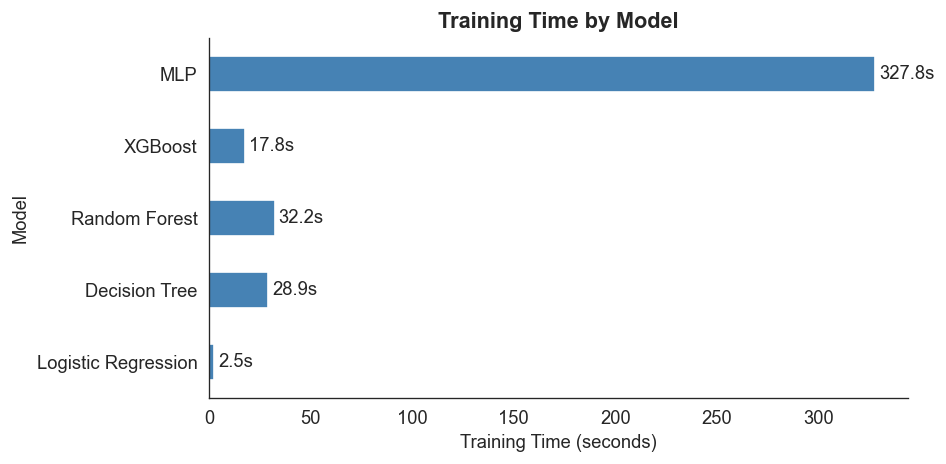

In [36]:
# --- 7.1b Training time comparison ---
import seaborn as sns
time_df = comparison_df.loc[MODEL_NAMES, ['Train Time (s)']]

fig, ax = plt.subplots(figsize=(8, 4))
time_df.plot(kind='barh', ax=ax, color='steelblue', legend=False, edgecolor='white')
ax.set_xlabel('Training Time (seconds)')
ax.set_title('Training Time by Model')
for i, v in enumerate(time_df['Train Time (s)']):
    ax.text(v + 2, i, f'{v:.1f}s', va='center')
sns.despine()
plt.tight_layout()
save_fig('explore_training_times')
plt.show()

### 5.7.2 ROC Curves

Saved: explore_roc_curves_v2.png


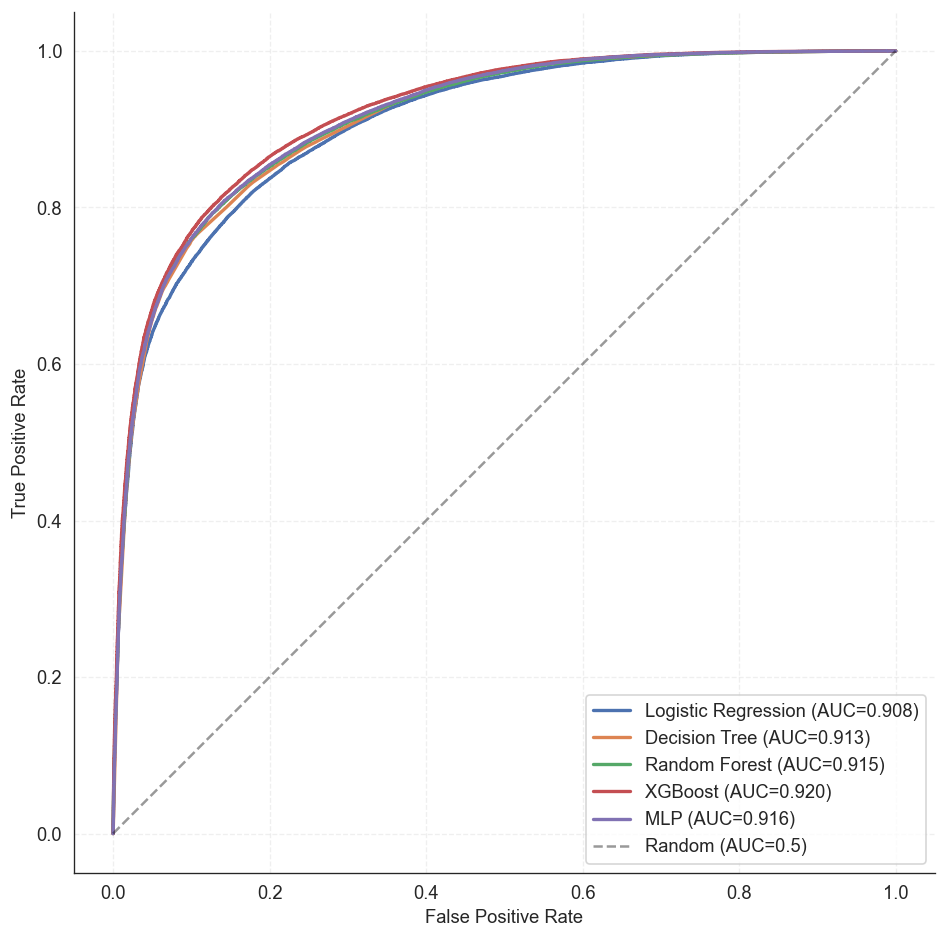

In [45]:
# --- 7.2 ROC Curves ---
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52', '#8172B3']

fig, ax = plt.subplots(figsize=(8, 8))
for name, color in zip(MODEL_NAMES, colors):
    proba = model_predictions[name]['y_proba']
    if proba is not None:
        fpr, tpr, _ = roc_curve(y_val, proba)
        auc_val = comparison_df.loc[name, 'Val AUC']
        ax.plot(fpr, tpr, label=f'{name} (AUC={auc_val:.3f})',
                color=color, linewidth=2)

ax.plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Random (AUC=0.5)')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
# ax.set_title('ROC Curves — Best Config per Model')
ax.legend(loc='lower right')
ax.set_aspect('equal')
ax.grid(True, alpha=0.3, linestyle='--')
sns.despine()
plt.tight_layout()
save_fig('explore_roc_curves')
plt.show()

### 5.7.3 Model Comparison — Accuracy, F1, AUC

In [44]:
# --- 7.3 Summary Table ---
summary_df = comparison_df.loc[MODEL_NAMES, ['Val AUC', 'F1', 'Overfit Gap', 'Train Time (s)']]
summary_df.round(4)

,Val AUC,F1,Overfit Gap,Train Time (s)
Model,,,,
Logistic Regression,0.9079,0.8468,0.0003,2.5
Decision Tree,0.9130,0.8339,0.0010,28.9
Random Forest,0.9150,0.8563,0.0632,32.2
XGBoost,0.9204,0.8551,0.0232,17.8
MLP,0.9158,0.8632,0.0085,327.8


**Observations:**
- **Logistic Regression:** Flat across all C values; regularisation strength has minimal impact, no overfitting
- **Decision Tree:** Severe overfitting at unlimited depth (train loss near 0, validation loss spikes to 8)
- **Random Forest:** Train-val gap widens with depth; moderate depth (10–20) balances fit and generalisation
- **XGBoost:** Lower learning rates (0.01, 0.1) more stable; higher rates overfit at greater depths
- **MLP:** Larger architectures overfit; simplest (50,) generalises better than (100,) or (100, 50)

---
## 5.8 Shortlisting Decision

Select models for Stage 5 based on validation AUC and F1, interpretability, and efficiency.
Research question prioritises understanding which factors drive recommendations,
so interpretable models are favoured alongside one complex model for comparison.

**Models advancing to next stage:**

| Model | Val AUC | Val F1 | Rationale |
|-------|---------|-----|-----------|
| Logistic Regression | 0.908 | 0.847 | Coefficients answer "which factors matter?" directly |
| Decision Tree | 0.913 | 0.834 | Visual decision rules, strong AUC, minimal overfitting |
| XGBoost | 0.920 | 0.855 | Best AUC; complex model for comparison with interpretable baselines |

**Models dropped:**

| Model | Reason |
|-------|--------|
| Random Forest | XGBoost outperforms (0.920 vs 0.915 AUC); highest overfitting (6.3%); one tree ensemble sufficient |
| MLP | 18× slower than XGBoost for lower AUC; no class weighting support |

**Rationale:** Two interpretable models (LR, DT) answer the research question directly. 
XGBoost provides a sophisticated comparison point to test whether added complexity significantly 
improves prediction.